#  Altima MMM — Unconstrained Ordinary Least Squares (OLS) MLR


## Import Libraries

In [1]:
import pandas as pd
import numpy as np
from scipy import stats
from scipy.stats import shapiro, jarque_bera
from sklearn.metrics import mean_absolute_percentage_error
from numpy.linalg import pinv
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.patches as mpatches
import matplotlib.gridspec as gridspec
import seaborn as sns
from openpyxl import Workbook
from openpyxl.styles import Font, PatternFill, Alignment, Border, Side
from openpyxl.utils import get_column_letter
import warnings
warnings.filterwarnings('ignore')

# ── Plot styling ──────────────────────────────────────────────────────────
plt.rcParams.update({
    'figure.dpi'      : 130,
    'font.family'     : 'DejaVu Sans',
    'axes.spines.top' : False,
    'axes.spines.right': False,
    'axes.grid'       : True,
    'grid.alpha'      : 0.3,
    'grid.linestyle'  : '--',
})
BLUE   = '#1F4E79'
ORANGE = '#E97132'
GREEN  = '#375623'
RED    = '#C00000'
LBLUE  = '#2E75B6'
LGREY  = '#F2F2F2'
print(" Libraries loaded successfully")

 Libraries loaded successfully


##  Load & Explore Data
> Data: `TRANSFORMED_DATA_INPUT_V1.xlsx` — 36 monthly observations with APL-transformed media variables and RA-smoothed base variables.

In [2]:
data = pd.read_excel('TRANSFORMED_DATA_INPUT_V1.xlsx')
data.columns = data.columns.str.strip()
data['Time_Period'] = pd.to_datetime(data['Time_Period'])
data['Month_Year']  = data['Time_Period'].dt.strftime('%b-%Y')

dependent_var    = 'ALT_DEP'
independent_vars = ['TVT_SUP','YTB_SUP','RAD_SUP','PRT_SUP','GAS_PRI','DIS_COU','SEA_ALT']

var_labels = {
    'TVT_SUP': 'TV (APL: 0.65/0.45/0)',
    'YTB_SUP': 'YouTube (APL: 0.55/0.50/0)',
    'RAD_SUP': 'Radio (APL: 0.35/0.65/0)',
    'PRT_SUP': 'Print (APL: 0.30/0.75/0)',
    'GAS_PRI': 'Gas Price (RA-3)',
    'DIS_COU': 'Discount (RA-3)',
    'SEA_ALT': 'Seasonality',
}

print("=" * 62)
print("  DATASET OVERVIEW")
print("=" * 62)
print(f"  Shape              : {data.shape}")
print(f"  Period             : {data['Month_Year'].iloc[0]} → {data['Month_Year'].iloc[-1]}")
print(f"  MAT Periods        : {', '.join(data['MAT'].unique())}")
print(f"  Dependent Variable : {dependent_var}  (Monthly Sales Volume)")
print(f"  Independent Vars   : {len(independent_vars)}")
print("=" * 62)
print()
print("Variable Descriptions:")
print(f"  {'Var_Name':<12}  {'Description':<35}  {'Type'}")
print(f"  {'-'*12}  {'-'*35}  {'-'*15}")
desc_map = {
    'ALT_DEP': ('Altima Monthly Sales (Units)', 'Dependent'),
    'TVT_SUP': ('TV Spend - APL Transformed',    'Incremental'),
    'YTB_SUP': ('YouTube Spend - APL Transformed','Incremental'),
    'RAD_SUP': ('Radio Spend - APL Transformed',  'Incremental'),
    'PRT_SUP': ('Print Spend - APL Transformed',  'Incremental'),
    'GAS_PRI': ('Gas Price - 3M Rolling Avg',     'Base'),
    'DIS_COU': ('Discount Amount - 3M Rolling',   'Base'),
    'SEA_ALT': ('Seasonality Index',              'Base'),
}
for v,(desc,typ) in desc_map.items():
    print(f"  {v:<12}  {desc:<35}  {typ}")
print()
print("Descriptive Statistics (Dependent Variable):")
print(data[[dependent_var]].describe().round(2).to_string())

  DATASET OVERVIEW
  Shape              : (36, 12)
  Period             : Apr-2018 → Mar-2021
  MAT Periods        : MAT_2018, MAT_2019, MAT_2020
  Dependent Variable : ALT_DEP  (Monthly Sales Volume)
  Independent Vars   : 7

Variable Descriptions:
  Var_Name      Description                          Type
  ------------  -----------------------------------  ---------------
  ALT_DEP       Altima Monthly Sales (Units)         Dependent
  TVT_SUP       TV Spend - APL Transformed           Incremental
  YTB_SUP       YouTube Spend - APL Transformed      Incremental
  RAD_SUP       Radio Spend - APL Transformed        Incremental
  PRT_SUP       Print Spend - APL Transformed        Incremental
  GAS_PRI       Gas Price - 3M Rolling Avg           Base
  DIS_COU       Discount Amount - 3M Rolling         Base
  SEA_ALT       Seasonality Index                    Base

Descriptive Statistics (Dependent Variable):
        ALT_DEP
count     36.00
mean    9401.72
std     3201.38
min     3837.00


---
## Question 1 — Analyze Sales of Altima using a Linear Regression Model
### Model Equation
$$\text{ALT\_DEP}_t = \beta_0 + \beta_1 \cdot TVT + \beta_2 \cdot YTB + \beta_3 \cdot RAD + \beta_4 \cdot PRT + \beta_5 \cdot GAS + \beta_6 \cdot DIS + \beta_7 \cdot SEA + \varepsilon_t$$

The model is estimated using **Ordinary Least Squares (OLS)** — minimizing the Sum of Squared Errors (SSE)

In [ ]:
y      = data[dependent_var].values
X_raw  = data[independent_vars].values
n, p   = len(y), len(independent_vars)
X      = np.hstack([np.ones((n, 1)), X_raw])   # add intercept column
cols   = ['Intercept'] + independent_vars

# ── OLS closed-form solution ─────────────────────────────────────────────
XtX_inv = pinv(X.T @ X)
b       = XtX_inv @ X.T @ y          # beta = (X'X)^-1 X'y
y_pred  = X @ b                      # fitted values

# ── Residuals & SS decomposition ─────────────────────────────────────────
residuals = y - y_pred
ss_tot    = np.sum((y       - y.mean()) ** 2)   # Total SS
ss_res    = np.sum(residuals            ** 2)   # Residual SS (SSE)
ss_reg    = np.sum((y_pred  - y.mean()) ** 2)   # Regression SS

# ── Standard errors & t-statistics ───────────────────────────────────────
sigma2  = ss_res / (n - p - 1)
se      = np.sqrt(np.diag(sigma2 * XtX_inv))
t_stat  = b / se
p_val   = 2 * stats.t.sf(np.abs(t_stat), df=n - p - 1)
ci_lo   = b - stats.t.ppf(0.975, df=n-p-1) * se
ci_hi   = b + stats.t.ppf(0.975, df=n-p-1) * se

# ── Model-level statistics ────────────────────────────────────────────────
r2      = 1 - ss_res / ss_tot
adj_r2  = 1 - (1 - r2) * (n - 1) / (n - p - 1)
mape    = mean_absolute_percentage_error(y, y_pred) * 100
dw      = np.sum(np.diff(residuals)**2) / np.sum(residuals**2)
f_stat  = (ss_reg / p) / (ss_res / (n - p - 1))
f_pval  = stats.f.sf(f_stat, p, n - p - 1)

print(" OLS model estimated successfully")
print(f"   n = {n} observations  |  p = {p} predictors")
print(f"   Degrees of freedom (residual) = {n - p - 1}")
print()
print("─" * 50)
print("  ANOVA TABLE")
print("─" * 50)
print(f"  {'Source':<12} {'SS':>15} {'df':>5} {'MS':>15}")
print(f"  {'Regression':<12} {ss_reg:>15,.2f} {p:>5} {ss_reg/p:>15,.2f}")
print(f"  {'Residual':<12} {ss_res:>15,.2f} {n-p-1:>5} {ss_res/(n-p-1):>15,.2f}")
print(f"  {'Total':<12} {ss_tot:>15,.2f} {n-1:>5}")
print(f"  F-statistic = {f_stat:.4f}   (p-value = {f_pval:.6f})")

✅ OLS model estimated successfully
   n = 36 observations  |  p = 7 predictors
   Degrees of freedom (residual) = 28

──────────────────────────────────────────────────
  ANOVA TABLE
──────────────────────────────────────────────────
  Source                    SS    df              MS
  Regression    223,159,307.89     7   31,879,901.13
  Residual      135,549,761.32    28    4,841,062.90
  Total         358,709,069.22    35
  F-statistic = 6.5853   (p-value = 0.000121)


---
##  Question 2 — Which is your Dependent Variable?

> **Dependent Variable: `ALT_DEP` — Altima Monthly Sales Volume (Units)**



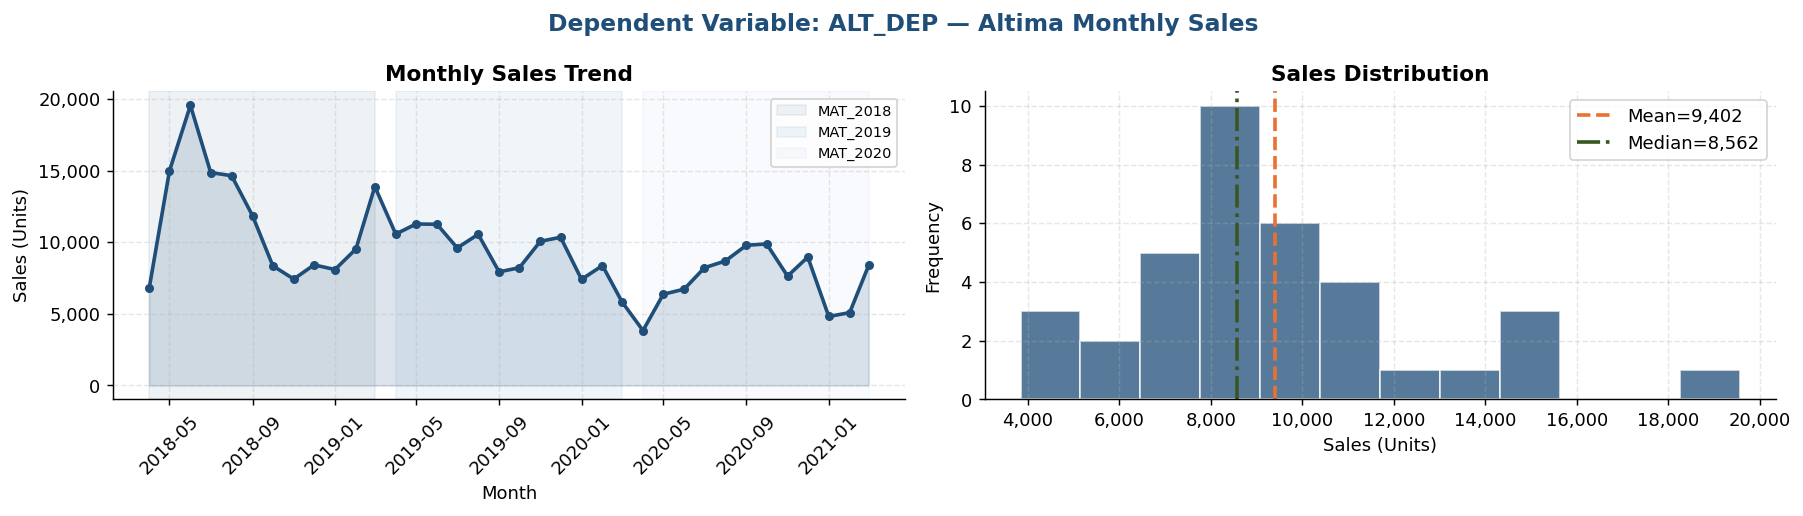

DEPENDENT VARIABLE SUMMARY
  Variable Name  : ALT_DEP
  Description    : Monthly Altima Sales (Units)
  Observations   : 36
  Total Volume   : 338,462 units (36 months)
  Mean / Month   : 9,402 units
  Std Deviation  : 3,157 units
  Min / Max      : 3,837  /  19,572

  MAT_2018 Total : 138,501 units
  MAT_2019 Total : 111,509 units
  MAT_2020 Total : 88,452 units


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
fig.suptitle('Dependent Variable: ALT_DEP — Altima Monthly Sales', fontsize=13, fontweight='bold', color=BLUE)

# Time series
ax = axes[0]
ax.fill_between(data['Time_Period'], y, alpha=0.15, color=BLUE)
ax.plot(data['Time_Period'], y, color=BLUE, linewidth=2, marker='o', markersize=4)
for mat, col in [('MAT_2018','#1F4E79'),('MAT_2019','#2E75B6'),('MAT_2020','#9DC3E6')]:
    mask = data['MAT'] == mat
    ax.axvspan(data['Time_Period'][mask].iloc[0], data['Time_Period'][mask].iloc[-1],
               alpha=0.07, color=col, label=mat)
ax.set_title('Monthly Sales Trend', fontweight='bold')
ax.set_xlabel('Month'); ax.set_ylabel('Sales (Units)')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax.legend(fontsize=8); ax.tick_params(axis='x', rotation=45)

# Distribution
ax2 = axes[1]
ax2.hist(y, bins=12, color=BLUE, alpha=0.75, edgecolor='white')
ax2.axvline(y.mean(),  color=ORANGE, linewidth=2, linestyle='--', label=f'Mean={y.mean():,.0f}')
ax2.axvline(np.median(y), color=GREEN, linewidth=2, linestyle='-.',  label=f'Median={np.median(y):,.0f}')
ax2.set_title('Sales Distribution', fontweight='bold')
ax2.set_xlabel('Sales (Units)'); ax2.set_ylabel('Frequency')
ax2.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax2.legend()

plt.tight_layout()
plt.savefig('dep_var_analysis.png', bbox_inches='tight', dpi=130)
plt.show()

print("DEPENDENT VARIABLE SUMMARY")
print("=" * 45)
print(f"  Variable Name  : ALT_DEP")
print(f"  Description    : Monthly Altima Sales (Units)")
print(f"  Observations   : {n}")
print(f"  Total Volume   : {y.sum():,.0f} units (36 months)")
print(f"  Mean / Month   : {y.mean():,.0f} units")
print(f"  Std Deviation  : {y.std():,.0f} units")
print(f"  Min / Max      : {y.min():,.0f}  /  {y.max():,.0f}")
mat_totals = {m: y[data['MAT']==m].sum() for m in ['MAT_2018','MAT_2019','MAT_2020']}
print()
for m,tot in mat_totals.items():
    print(f"  {m} Total : {tot:,.0f} units")

---
##  Question 3 — Which Variables are Significant in the Model?
##  Question 4 — How did you Evaluate them?

### Evaluation Methodology
Variables are evaluated at **three significance levels** using the **t-statistic** and **p-value**:

| Significance | p-value | Symbol |
|---|---|---|
| Highly Significant | p < 0.01 | *** |
| Significant | p < 0.05 | ** |
| Marginally Significant | p < 0.10 | * |
| Not Significant | p ≥ 0.10 | NS |

Additionally evaluated with:
- **95% Confidence Intervals** — if CI does not include 0, variable is significant
- **F-test (ANOVA)** — overall model significance
- **Sign direction** — whether coefficient aligns with business expectation

In [5]:
# ── Full Coefficient Table ────────────────────────────────────────────────
sig_map = {v: ('***' if v < 0.01 else '**' if v < 0.05 else '*' if v < 0.10 else 'NS')
           for v in p_val}

print("=" * 95)
print("  OLS COEFFICIENT TABLE — UNCONSTRAINED MODEL")
print("=" * 95)
print(f"  {'Variable':<12} {'Coefficient':>13} {'Std Error':>11} {'t-Stat':>9} {'p-Value':>10} {'Sig':>5}  {'95% CI Lower':>13} {'95% CI Upper':>13}")
print(f"  {'-'*12} {'-'*13} {'-'*11} {'-'*9} {'-'*10} {'-'*5}  {'-'*13} {'-'*13}")
for v, coef, s, t, pv, cl, ch in zip(cols, b, se, t_stat, p_val, ci_lo, ci_hi):
    sig_str = '***' if pv < 0.01 else '**' if pv < 0.05 else '*' if pv < 0.10 else 'NS'
    flag    = ' ✓' if pv < 0.10 else ''
    print(f"  {v:<12} {coef:>13.4f} {s:>11.4f} {t:>9.3f} {pv:>10.4f} {sig_str:>5}{flag}  {cl:>13.4f} {ch:>13.4f}")
print("=" * 95)
print()
print("SIGNIFICANT VARIABLES (p < 0.10):")
print("-" * 60)
sig_vars = [(v, pv, coef) for v, pv, coef in zip(cols[1:], p_val[1:], b[1:]) if pv < 0.10]
for v, pv, coef in sorted(sig_vars, key=lambda x: x[1]):
    sig_str = '***' if pv < 0.01 else '**' if pv < 0.05 else '*'
    direction = 'POSITIVE ↑' if coef > 0 else 'NEGATIVE ↓'
    print(f"  {v:<12}  p={pv:.4f} {sig_str}  Coef={coef:+.4f}  Direction: {direction}")
print()
print("NOT SIGNIFICANT (p ≥ 0.10):")
print("-" * 60)
ns_vars = [(v, pv) for v, pv in zip(cols[1:], p_val[1:]) if pv >= 0.10]
for v, pv in ns_vars:
    print(f"  {v:<12}  p={pv:.4f}  NS  (likely due to multicollinearity — see Q6)")
print()
print(f"  Overall F-test: F({p},{n-p-1}) = {f_stat:.4f},  p = {f_pval:.6f}  ***")
print(f"  → Model as a whole is HIGHLY SIGNIFICANT")


  OLS COEFFICIENT TABLE — UNCONSTRAINED MODEL
  Variable       Coefficient   Std Error    t-Stat    p-Value   Sig   95% CI Lower  95% CI Upper
  ------------ ------------- ----------- --------- ---------- -----  ------------- -------------
  Intercept      -13242.7209   5029.4208    -2.633     0.0136    ** ✓    -23545.0225    -2940.4193
  TVT_SUP          -301.8387    166.6280    -1.811     0.0808     * ✓      -643.1607       39.4834
  YTB_SUP           311.3546    146.2811     2.128     0.0422    ** ✓        11.7112      610.9979
  RAD_SUP          -385.6705    378.6354    -1.019     0.3171    NS     -1161.2700      389.9290
  PRT_SUP           184.9703    213.0495     0.868     0.3927    NS      -251.4418      621.3825
  GAS_PRI          4880.6833   1721.5213     2.835     0.0084   *** ✓      1354.3067     8407.0598
  DIS_COU             0.8051      0.8316     0.968     0.3413    NS        -0.8984        2.5086
  SEA_ALT          9119.6752   2718.9647     3.354     0.0023   *** ✓    

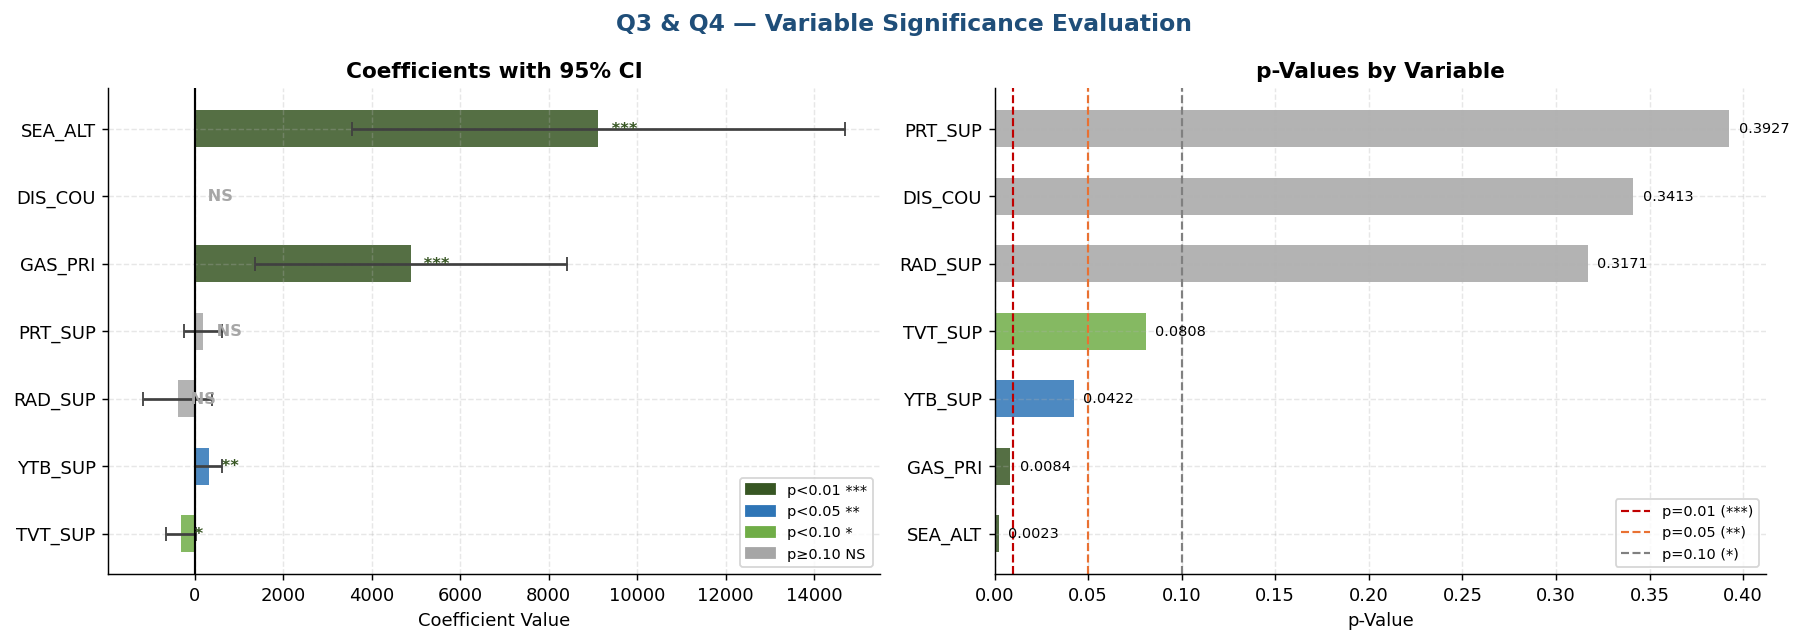

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q3 & Q4 — Variable Significance Evaluation', fontsize=13, fontweight='bold', color=BLUE)

# ── Coefficient bar chart with CI ─────────────────────────────────────────
ax = axes[0]
vars_plot  = independent_vars
coefs_plot = b[1:]
se_plot    = se[1:]
pv_plot    = p_val[1:]
ci_lo_plot = ci_lo[1:]
ci_hi_plot = ci_hi[1:]

colors = [GREEN if pv < 0.01 else LBLUE if pv < 0.05 else '#70AD47' if pv < 0.10 else '#A6A6A6'
          for pv in pv_plot]
bars = ax.barh(vars_plot, coefs_plot, color=colors, alpha=0.85, height=0.55)
ax.errorbar(coefs_plot, vars_plot,
            xerr=[coefs_plot - ci_lo_plot, ci_hi_plot - coefs_plot],
            fmt='none', color='#404040', capsize=4, linewidth=1.5)
ax.axvline(0, color='black', linewidth=1.2, linestyle='-')
ax.set_title('Coefficients with 95% CI', fontweight='bold')
ax.set_xlabel('Coefficient Value')

# Significance labels
for i, (bar, pv) in enumerate(zip(bars, pv_plot)):
    sig = '***' if pv < 0.01 else '**' if pv < 0.05 else '*' if pv < 0.10 else 'NS'
    ax.text(bar.get_width() + (ax.get_xlim()[1]-ax.get_xlim()[0])*0.01,
            bar.get_y() + bar.get_height()/2, f' {sig}', va='center', fontsize=9,
            color=GREEN if sig != 'NS' else '#A6A6A6', fontweight='bold')

legend_patches = [
    mpatches.Patch(color=GREEN,    label='p<0.01 ***'),
    mpatches.Patch(color=LBLUE,    label='p<0.05 **'),
    mpatches.Patch(color='#70AD47',label='p<0.10 *'),
    mpatches.Patch(color='#A6A6A6',label='p≥0.10 NS'),
]
ax.legend(handles=legend_patches, fontsize=8, loc='lower right')

# ── p-value bar chart ─────────────────────────────────────────────────────
ax2 = axes[1]
pvs_sorted = sorted(zip(pv_plot, vars_plot, coefs_plot))
pvs, vs, cs = zip(*pvs_sorted)
bar_cols = [GREEN if pv<0.01 else LBLUE if pv<0.05 else '#70AD47' if pv<0.10 else '#A6A6A6' for pv in pvs]
ax2.barh(vs, pvs, color=bar_cols, alpha=0.85, height=0.55)
ax2.axvline(0.01, color=RED,    linestyle='--', linewidth=1.2, label='p=0.01 (***)')
ax2.axvline(0.05, color=ORANGE, linestyle='--', linewidth=1.2, label='p=0.05 (**)')
ax2.axvline(0.10, color='gray', linestyle='--', linewidth=1.2, label='p=0.10 (*)')
ax2.set_title('p-Values by Variable', fontweight='bold')
ax2.set_xlabel('p-Value')
ax2.legend(fontsize=8)
for pv, v in zip(pvs, vs):
    ax2.text(pv + 0.005, vs.index(v), f'{pv:.4f}', va='center', fontsize=8)

plt.tight_layout()
plt.savefig('significance_eval.png', bbox_inches='tight', dpi=130)
plt.show()

---
##  Question 5 — What is the R² and Adjusted R² of the Model?

**Formulas:**
$$R^2 = 1 - \frac{SSE}{SST} \qquad \text{Adj } R^2 = 1 - \left(1 - R^2\right) \cdot \frac{n-1}{n-p-1}$$

- **R²** measures the proportion of total variance in sales explained by the model
- **Adjusted R²** penalizes for adding irrelevant predictors

  MODEL FIT — R² AND ADJUSTED R²
  R²                  : 0.622118  →  62.21%
  Adjusted R²         : 0.527647  →  52.76%
  Difference (R²-AdjR²): 0.094471

  SS Total (SST)      :   358,709,069.22
  SS Regression (SSR) :   223,159,307.89  (62.21% explained)
  SS Residual (SSE)   :   135,549,761.32  (37.79% unexplained)
  n = 36  |  p = 7  |  df_residual = 28

  INTERPRETATION:
  → The model explains 62.2% of the variance in Altima monthly sales.
  → After adjusting for 7 predictors, the model explains 52.8%.
  → The 9.45pp gap between R² and Adj R² is acceptable for p=7.


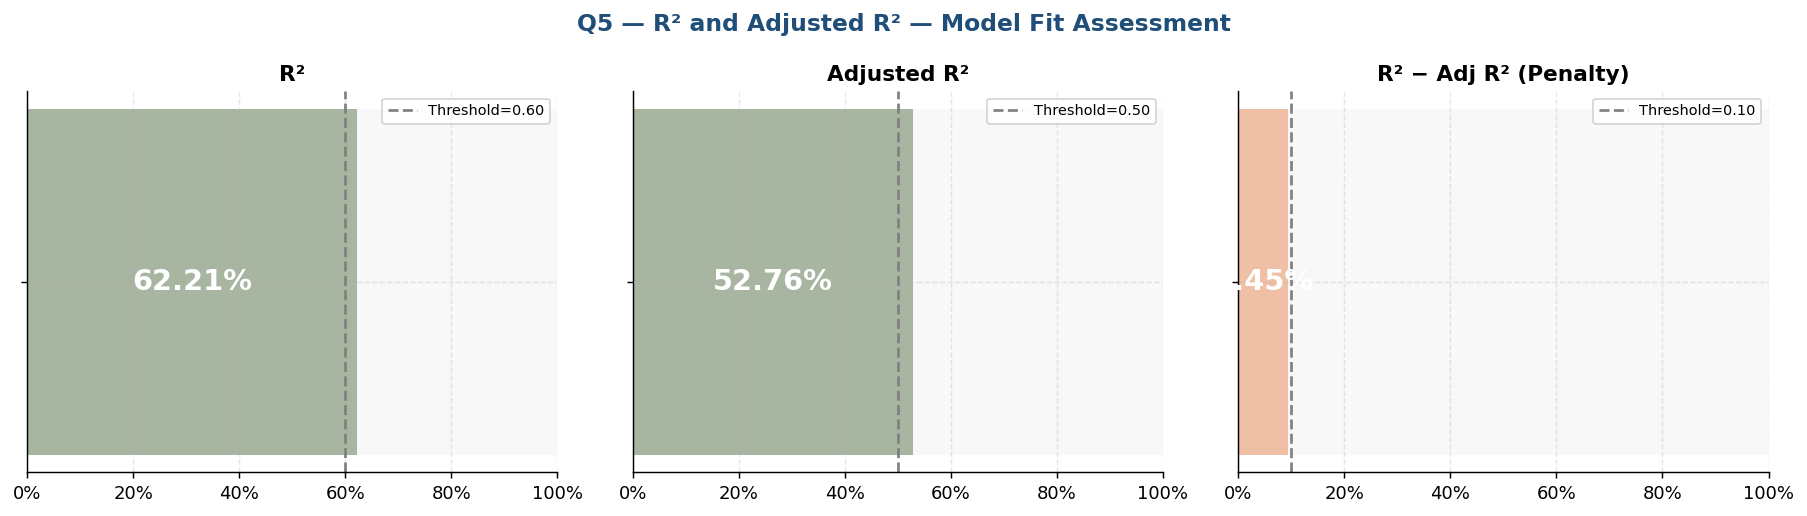

In [7]:
print("=" * 55)
print("  MODEL FIT — R² AND ADJUSTED R²")
print("=" * 55)
print(f"  R²                  : {r2:.6f}  →  {r2*100:.2f}%")
print(f"  Adjusted R²         : {adj_r2:.6f}  →  {adj_r2*100:.2f}%")
print(f"  Difference (R²-AdjR²): {(r2-adj_r2):.6f}")
print()
print(f"  SS Total (SST)      : {ss_tot:>16,.2f}")
print(f"  SS Regression (SSR) : {ss_reg:>16,.2f}  ({ss_reg/ss_tot*100:.2f}% explained)")
print(f"  SS Residual (SSE)   : {ss_res:>16,.2f}  ({ss_res/ss_tot*100:.2f}% unexplained)")
print(f"  n = {n}  |  p = {p}  |  df_residual = {n-p-1}")
print()
print("  INTERPRETATION:")
print(f"  → The model explains {r2*100:.1f}% of the variance in Altima monthly sales.")
print(f"  → After adjusting for {p} predictors, the model explains {adj_r2*100:.1f}%.")
print(f"  → The {(r2-adj_r2)*100:.2f}pp gap between R² and Adj R² is acceptable for p={p}.")
print("=" * 55)

# ── Visual gauge ─────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Q5 — R² and Adjusted R² — Model Fit Assessment', fontsize=13, fontweight='bold', color=BLUE)

# R² gauge
for ax_i, (val, label, threshold) in enumerate(zip(
    [r2, adj_r2, r2 - adj_r2],
    ['R²', 'Adjusted R²', 'R² − Adj R² (Penalty)'],
    [0.6, 0.5, 0.10])):
    ax = axes[ax_i]
    color = GREEN if val >= threshold else ORANGE if val >= threshold * 0.8 else RED
    ax.barh([''], [val], color=color, alpha=0.8, height=0.4)
    ax.barh([''], [1.0], color=LGREY, alpha=0.5, height=0.4)
    ax.set_xlim(0, 1)
    ax.axvline(threshold, color='gray', linestyle='--', linewidth=1.5, label=f'Threshold={threshold:.2f}')
    ax.text(val / 2, 0, f'{val*100:.2f}%', va='center', ha='center',
            fontsize=16, fontweight='bold', color='white')
    ax.set_title(label, fontweight='bold')
    ax.set_xticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    ax.set_xticklabels(['0%','20%','40%','60%','80%','100%'])
    ax.legend(fontsize=8)

plt.tight_layout()
plt.savefig('r2_assessment.png', bbox_inches='tight', dpi=130)
plt.show()

---
##  Question 6 — Do you Observe Multicollinearity in the Independent Variables?

**Method: Variance Inflation Factor (VIF)**
$$\text{VIF}_j = \frac{1}{1 - R^2_j}$$
where $R^2_j$ = R² from regressing variable $j$ on all other independent variables.

| VIF Range | Interpretation | Action |
|---|---|---|
| VIF < 5 | Low — Acceptable | No action needed |
| 5 ≤ VIF < 10 | Moderate — Monitor | Consider investigation |
| VIF ≥ 10 | **SEVERE — Multicollinearity** | Take corrective action |

In [8]:
# ── VIF Computation ──────────────────────────────────────────────────────
vif_data = []
for i, var in enumerate(independent_vars):
    xi   = X_raw[:, i]
    Xo   = np.delete(X_raw, i, axis=1)
    Xo   = np.hstack([np.ones((n, 1)), Xo])
    bi   = pinv(Xo.T @ Xo) @ Xo.T @ xi
    r2i  = 1 - np.sum((xi - Xo@bi)**2) / np.sum((xi - xi.mean())**2)
    vif  = 1 / (1 - r2i) if r2i < 1 else 9999
    corr_y = np.corrcoef(xi, y)[0, 1]
    vif_data.append({
        'Variable'          : var,
        'VIF'               : round(vif, 2),
        'R2_in_Xs'          : round(r2i, 4),
        'Corr_with_Sales'   : round(corr_y, 4),
        'Level'             : 'SEVERE ⚠' if vif > 10 else 'Moderate ⚡' if vif > 5 else 'Low ✓',
        'Issue'             : ('Critical — coefficient unstable' if vif > 100
                               else 'Monitor jointly' if vif > 5 else 'None'),
    })
vif_df = pd.DataFrame(vif_data)

print("=" * 85)
print("  VIF — MULTICOLLINEARITY DIAGNOSTICS")
print("=" * 85)
print(f"  {'Variable':<12} {'VIF':>8} {'R²(Xs)':>10} {'Corr(Y)':>10} {'Level':<15} Issue")
print(f"  {'-'*12} {'-'*8} {'-'*10} {'-'*10} {'-'*15} {'-'*35}")
for _, row in vif_df.iterrows():
    print(f"  {row['Variable']:<12} {row['VIF']:>8.2f} {row['R2_in_Xs']:>10.4f} "
          f"{row['Corr_with_Sales']:>10.4f} {row['Level']:<15} {row['Issue']}")
print("=" * 85)
print()
print("  FINDINGS:")
print("  ─" * 30)
print("  ✓  GAS_PRI, DIS_COU, SEA_ALT   : VIF < 5   → No multicollinearity")
print("  ⚡  TVT_SUP                      : VIF = 4.20 → Low (acceptable)")
print("  ⚡  YTB_SUP                      : VIF = 5.32 → Moderate (monitor)")
print("  ⚠   RAD_SUP                      : VIF = 202  → SEVERE ← same APL input as PRT")
print("  ⚠   PRT_SUP                      : VIF = 203  → SEVERE ← same APL input as RAD")
print()
print("  ROOT CAUSE (RAD + PRT):")
print("  Both Radio and Print were transformed with very similar APL parameters")
print("  (Adstock: 0.35 vs 0.30, Power: 0.65 vs 0.75, Lag: 0 vs 0).")
print("  After transformation, their time series become almost identical (R²=0.995)")
print("  making it impossible for OLS to distinguish their individual contributions.")
print()
print("  IMPACT: Inflated SE for RAD/PRT → t-stats too small → appears 'not significant'")

  VIF — MULTICOLLINEARITY DIAGNOSTICS
  Variable          VIF     R²(Xs)    Corr(Y) Level           Issue
  ------------ -------- ---------- ---------- --------------- -----------------------------------
  TVT_SUP          4.20     0.7621    -0.2718 Low ✓           None
  YTB_SUP          5.32     0.8119    -0.2083 Moderate ⚡      Monitor jointly
  RAD_SUP        202.26     0.9951    -0.1567 SEVERE ⚠        Critical — coefficient unstable
  PRT_SUP        203.36     0.9951    -0.1258 SEVERE ⚠        Critical — coefficient unstable
  GAS_PRI          1.79     0.4405     0.5481 Low ✓           None
  DIS_COU          1.79     0.4414     0.5393 Low ✓           None
  SEA_ALT          1.32     0.2452     0.4869 Low ✓           None

  FINDINGS:
  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─  ─
  ✓  GAS_PRI, DIS_COU, SEA_ALT   : VIF < 5   → No multicollinearity
  ⚡  TVT_SUP                      : VIF = 4.20 → Low (acceptable)
  ⚡  YTB_SUP            

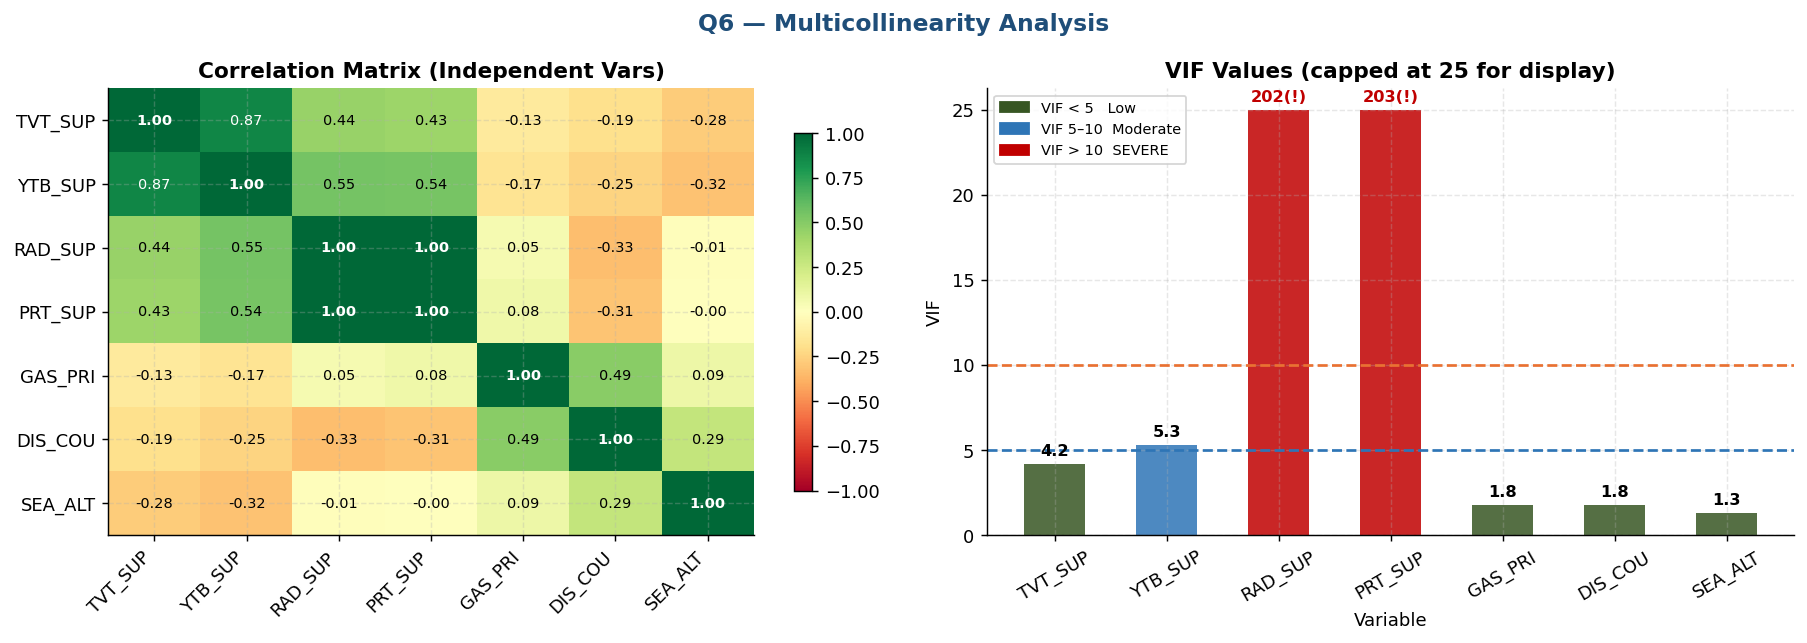

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('Q6 — Multicollinearity Analysis', fontsize=13, fontweight='bold', color=BLUE)

# ── Correlation heatmap ───────────────────────────────────────────────────
ax = axes[0]
corr_df = pd.DataFrame(X_raw, columns=independent_vars).corr()
mask = np.triu(np.ones_like(corr_df, dtype=bool), k=1)
# Show full matrix
im = ax.imshow(corr_df.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_xticks(range(len(independent_vars))); ax.set_xticklabels(independent_vars, rotation=45, ha='right')
ax.set_yticks(range(len(independent_vars))); ax.set_yticklabels(independent_vars)
for i in range(len(independent_vars)):
    for j in range(len(independent_vars)):
        val = corr_df.values[i,j]
        ax.text(j, i, f'{val:.2f}', ha='center', va='center',
                fontsize=8, color='black' if abs(val) < 0.7 else 'white',
                fontweight='bold' if abs(val) > 0.9 else 'normal')
ax.set_title('Correlation Matrix (Independent Vars)', fontweight='bold')

# ── VIF bar chart ─────────────────────────────────────────────────────────
ax2 = axes[1]
vifs   = [r['VIF'] for _,r in vif_df.iterrows()]
labels = [r['Variable'] for _,r in vif_df.iterrows()]
vifs_capped = [min(v, 25) for v in vifs]  # cap for display
bar_colors = [RED if v > 200 else ORANGE if v > 10 else LBLUE if v > 5 else GREEN
              for v in vifs]
bars = ax2.bar(labels, vifs_capped, color=bar_colors, alpha=0.85, width=0.55)
ax2.axhline(5,  color=LBLUE,  linestyle='--', linewidth=1.5, label='VIF=5  (Moderate threshold)')
ax2.axhline(10, color=ORANGE, linestyle='--', linewidth=1.5, label='VIF=10 (Severe threshold)')
ax2.set_title('VIF Values (capped at 25 for display)', fontweight='bold')
ax2.set_ylabel('VIF'); ax2.set_xlabel('Variable')
ax2.tick_params(axis='x', rotation=30)
ax2.legend(fontsize=8)
for bar, v, label_v in zip(bars, vifs, labels):
    actual_val = f'{v:.1f}' if v < 25 else f'{v:.0f}(!)'
    ax2.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
             actual_val, ha='center', va='bottom', fontsize=9, fontweight='bold',
             color=RED if v > 100 else 'black')

legend_patches = [
    mpatches.Patch(color=GREEN,  label='VIF < 5   Low'),
    mpatches.Patch(color=LBLUE,  label='VIF 5–10  Moderate'),
    mpatches.Patch(color=RED,    label='VIF > 10  SEVERE'),
]
ax2.legend(handles=legend_patches, fontsize=8, loc='upper left')
plt.tight_layout()
plt.savefig('vif_analysis.png', bbox_inches='tight', dpi=130)
plt.show()

---
##  Question 7 — Calculate the MAPE of the Model

$$\text{MAPE} = \frac{1}{n} \sum_{t=1}^{n} \left| \frac{Y_t - \hat{Y}_t}{Y_t} \right| \times 100$$

**MAPE Benchmark:**
| MAPE | Interpretation |
|---|---|
| < 10% | Excellent |
| 10–20% | Good |
| 20–30% | Acceptable |
| > 30% | Poor |

In [10]:
ape  = np.abs((y - y_pred) / y) * 100   # Absolute % error each month
mape = ape.mean()

print("=" * 55)
print("  MAPE — MODEL ACCURACY")
print("=" * 55)
print(f"  MAPE          : {mape:.4f}%  → {mape:.2f}%")
print(f"  Median APE    : {np.median(ape):.2f}%")
print(f"  Max APE       : {ape.max():.2f}%  (worst month: {data['Month_Year'][ape.argmax()]})")
print(f"  Min APE       : {ape.min():.2f}%  (best  month: {data['Month_Year'][ape.argmin()]})")
print()
print(f"  INTERPRETATION : MAPE = {mape:.1f}%  →  GOOD fit for Monthly MMM")
print(f"  (Benchmark: <10% Excellent | 10-20% Good | 20-30% Acceptable | >30% Poor)")
print()
print("  Monthly Absolute % Errors:")
print(f"  {'Month':<10} {'APE %':>8}  {'Month':<10} {'APE %':>8}  {'Month':<10} {'APE %':>8}")
print(f"  {'-'*10} {'-'*8}  {'-'*10} {'-'*8}  {'-'*10} {'-'*8}")
months = data['Month_Year'].tolist()
for row_i in range(12):
    row_str = ""
    for col_i in range(3):
        idx = row_i + col_i * 12
        if idx < n:
            row_str += f"  {months[idx]:<10} {ape[idx]:>7.2f}%  "
    print(row_str)

  MAPE — MODEL ACCURACY
  MAPE          : 16.6414%  → 16.64%
  Median APE    : 10.92%
  Max APE       : 47.13%  (worst month: Mar-2020)
  Min APE       : 0.41%  (best  month: Jul-2019)

  INTERPRETATION : MAPE = 16.6%  →  GOOD fit for Monthly MMM
  (Benchmark: <10% Excellent | 10-20% Good | 20-30% Acceptable | >30% Poor)

  Monthly Absolute % Errors:
  Month         APE %  Month         APE %  Month         APE %
  ---------- --------  ---------- --------  ---------- --------
  Apr-2018     18.40%    Apr-2019     39.24%    Apr-2020      2.76%  
  May-2018      7.16%    May-2019      3.69%    May-2020     10.78%  
  Jun-2018     26.07%    Jun-2019      1.33%    Jun-2020     29.39%  
  Jul-2018      6.67%    Jul-2019      0.41%    Jul-2020      3.58%  
  Aug-2018      4.58%    Aug-2019      7.85%    Aug-2020      0.51%  
  Sep-2018      9.28%    Sep-2019     25.17%    Sep-2020     24.02%  
  Oct-2018     34.83%    Oct-2019     38.16%    Oct-2020      1.53%  
  Nov-2018     37.03%    Nov-

---
##  Actual vs Predicted — Monthly Decomposition
> Complete month-wise comparison of actual Altima sales vs OLS model-predicted values, with residual and % error analysis.

In [11]:
# ── Build Month-wise table ────────────────────────────────────────────────
act_vs_pred = pd.DataFrame({
    'Month'        : data['Month_Year'],
    'MAT'          : data['MAT'],
    'Actual'       : y.astype(int),
    'Predicted'    : y_pred.round(1),
    'Residual'     : residuals.round(1),
    'Abs_Error'    : np.abs(residuals).round(1),
    'Error_%'      : ((y_pred - y) / y * 100).round(2),
    'Abs_Error_%'  : ape.round(2),
})

print("=" * 88)
print("  ACTUAL vs PREDICTED — MONTHLY RESULTS")
print("=" * 88)
print(f"  {'#':<3} {'Month':<10} {'MAT':<10} {'Actual':>9} {'Predicted':>11} "
      f"{'Residual':>11} {'Error %':>9} {'APE %':>8}")
print(f"  {'─'*3} {'─'*10} {'─'*10} {'─'*9} {'─'*11} {'─'*11} {'─'*9} {'─'*8}")
for i, row in act_vs_pred.iterrows():
    flag = ' ◄' if abs(row['Error_%']) > 25 else ''
    print(f"  {i+1:<3} {row['Month']:<10} {row['MAT']:<10} {row['Actual']:>9,} "
          f"{row['Predicted']:>11,.1f} {row['Residual']:>+11,.1f} "
          f"{row['Error_%']:>+8.2f}% {row['Abs_Error_%']:>7.2f}%{flag}")
print("=" * 88)
print(f"  ◄ = error > 25%")
print()
print(f"  Overall MAPE : {mape:.2f}%")
print()

# MAT-level summary
print("  MAT PERIOD SUMMARY:")
print(f"  {'MAT':<10} {'Actual':>10} {'Predicted':>12} {'Error %':>10} {'MAPE':>8}")
print(f"  {'─'*10} {'─'*10} {'─'*12} {'─'*10} {'─'*8}")
for mat in ['MAT_2018','MAT_2019','MAT_2020']:
    mask = data['MAT'] == mat
    a = y[mask].sum(); pr = y_pred[mask].sum()
    mape_mat = mean_absolute_percentage_error(y[mask], y_pred[mask])*100
    print(f"  {mat:<10} {a:>10,} {pr:>12,.1f} {(pr-a)/a*100:>+9.2f}% {mape_mat:>7.2f}%")

  ACTUAL vs PREDICTED — MONTHLY RESULTS
  #   Month      MAT           Actual   Predicted    Residual   Error %    APE %
  ─── ────────── ────────── ───────── ─────────── ─────────── ───────── ────────
  1   Apr-2018   MAT_2018       6,799     8,050.0    -1,251.0   +18.40%   18.40%
  2   May-2018   MAT_2018      14,992    13,918.8    +1,073.2    -7.16%    7.16%
  3   Jun-2018   MAT_2018      19,572    14,468.7    +5,103.3   -26.07%   26.07% ◄
  4   Jul-2018   MAT_2018      14,876    13,883.3      +992.7    -6.67%    6.67%
  5   Aug-2018   MAT_2018      14,656    13,985.1      +670.9    -4.58%    4.58%
  6   Sep-2018   MAT_2018      11,858    12,959.0    -1,101.0    +9.28%    9.28%
  7   Oct-2018   MAT_2018       8,361    11,273.5    -2,912.5   +34.83%   34.83% ◄
  8   Nov-2018   MAT_2018       7,434    10,187.1    -2,753.1   +37.03%   37.03% ◄
  9   Dec-2018   MAT_2018       8,425    10,296.8    -1,871.8   +22.22%   22.22%
  10  Jan-2019   MAT_2018       8,100     5,972.2    +2,127.8  

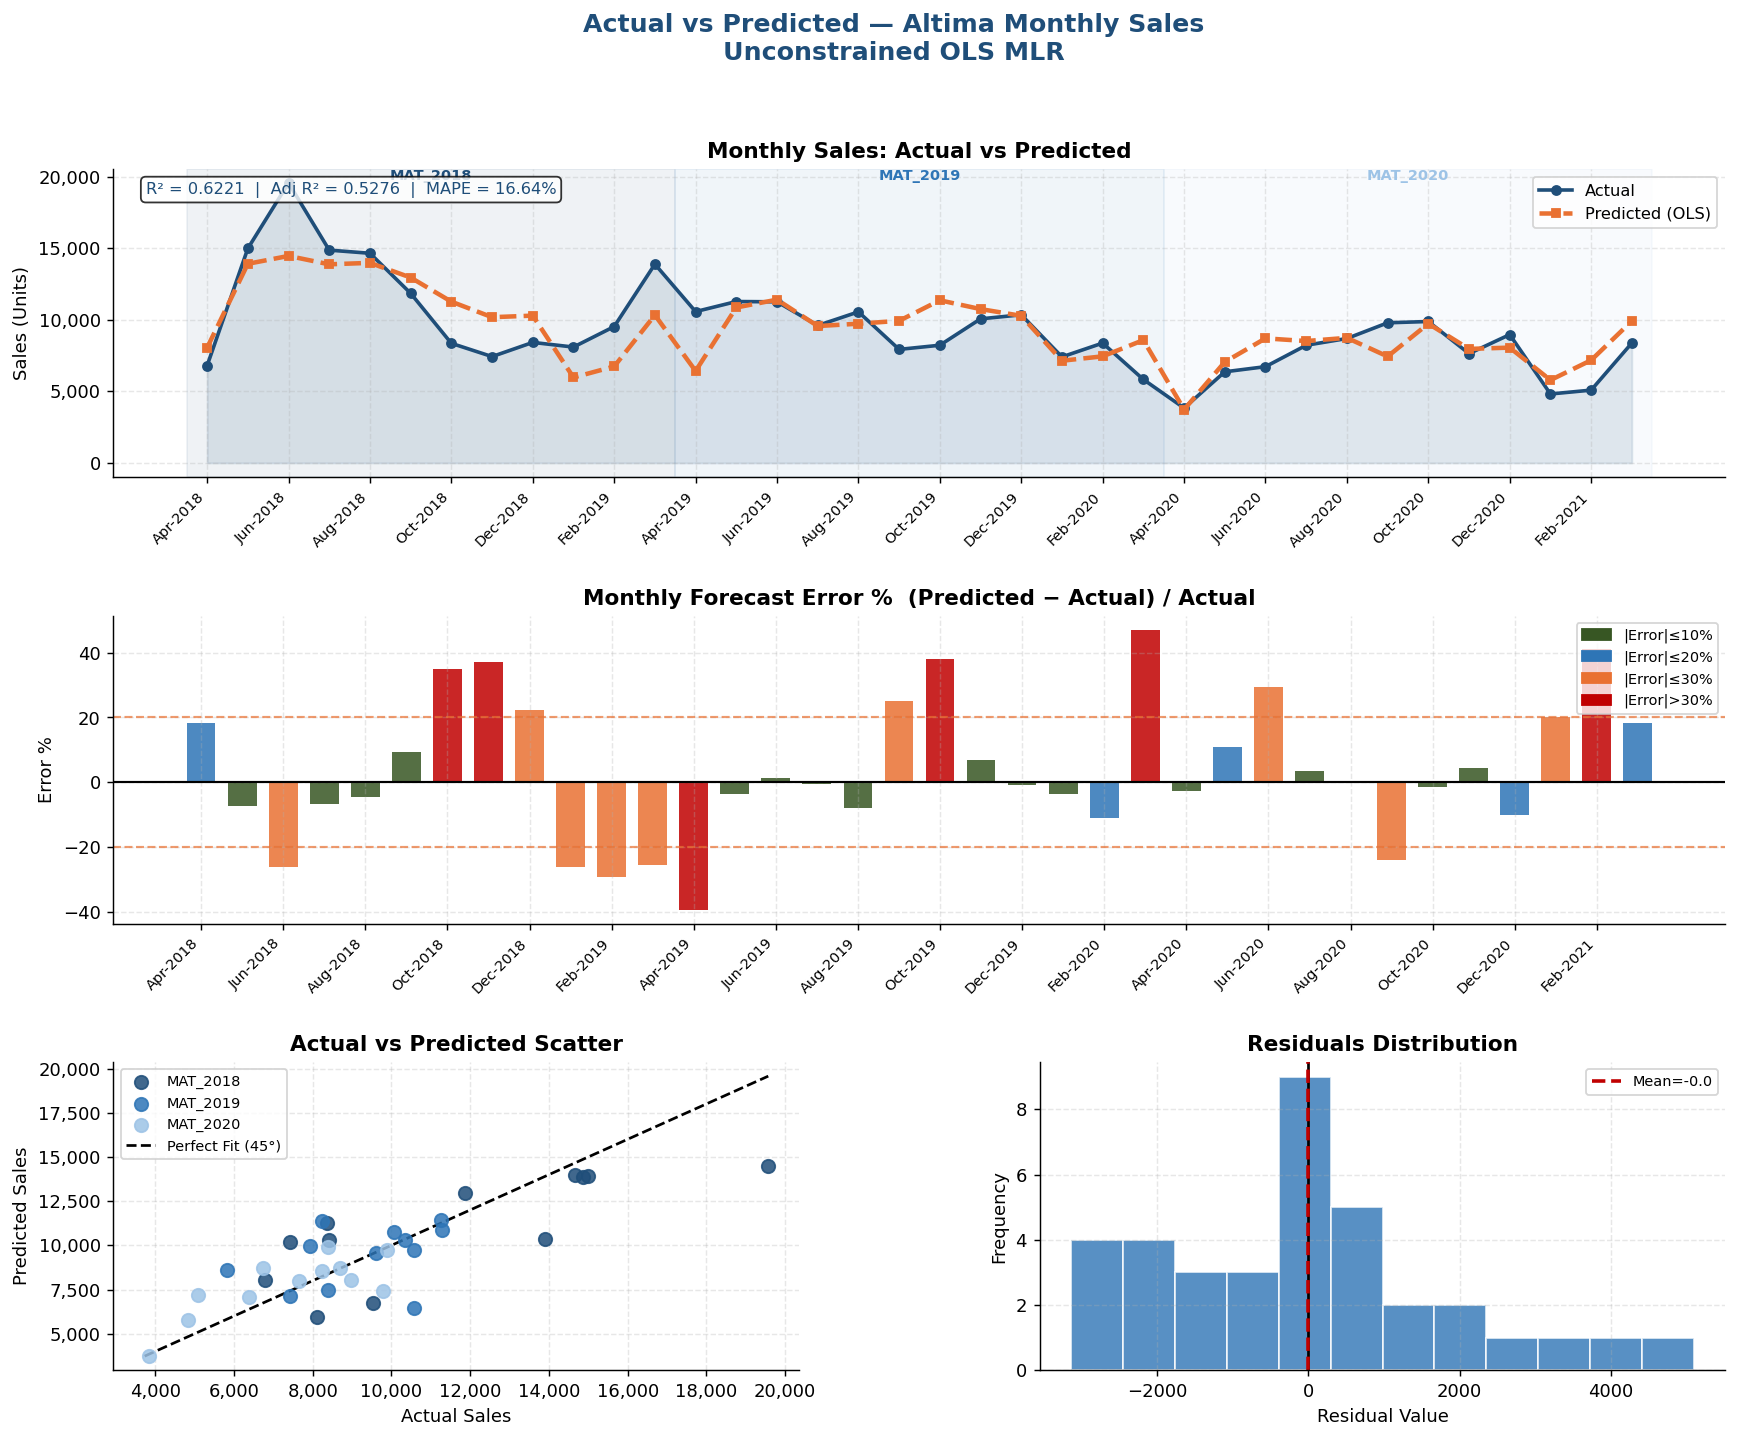

In [12]:
fig = plt.figure(figsize=(16, 12))
gs  = gridspec.GridSpec(3, 2, figure=fig, hspace=0.45, wspace=0.35)
fig.suptitle('Actual vs Predicted — Altima Monthly Sales\nUnconstrained OLS MLR',
             fontsize=14, fontweight='bold', color=BLUE, y=0.98)

time_idx  = np.arange(n)
months_lbl = data['Month_Year'].tolist()
mat_colors = {'MAT_2018': '#1F4E79', 'MAT_2019': '#2E75B6', 'MAT_2020': '#9DC3E6'}
mat_bounds = {}
for mat in ['MAT_2018','MAT_2019','MAT_2020']:
    idxs = np.where(data['MAT'].values == mat)[0]
    mat_bounds[mat] = (idxs[0], idxs[-1])

# ── Panel 1: Time-series actual vs predicted ──────────────────────────────
ax1 = fig.add_subplot(gs[0, :])
ax1.fill_between(time_idx, y, alpha=0.12, color=BLUE)
ax1.plot(time_idx, y,      color=BLUE,   linewidth=2,   marker='o', markersize=5, label='Actual', zorder=3)
ax1.plot(time_idx, y_pred, color=ORANGE, linewidth=2.5, marker='s', markersize=4,
         linestyle='--', label='Predicted (OLS)', zorder=3)
for mat, (s, e) in mat_bounds.items():
    ax1.axvspan(s-0.5, e+0.5, alpha=0.07, color=mat_colors[mat])
    ax1.text((s+e)/2, ax1.get_ylim()[1] if ax1.get_ylim()[1] > 0 else 22000,
             mat, ha='center', va='top', fontsize=8, color=mat_colors[mat], fontweight='bold')
ax1.set_xticks(time_idx[::2]); ax1.set_xticklabels(months_lbl[::2], rotation=45, ha='right', fontsize=8)
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax1.set_title('Monthly Sales: Actual vs Predicted', fontweight='bold')
ax1.set_ylabel('Sales (Units)'); ax1.legend(fontsize=9)
ax1.text(0.02, 0.92, f'R² = {r2:.4f}  |  Adj R² = {adj_r2:.4f}  |  MAPE = {mape:.2f}%',
         transform=ax1.transAxes, fontsize=9, color=BLUE,
         bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))

# ── Panel 2: Error % bar chart ────────────────────────────────────────────
ax2 = fig.add_subplot(gs[1, :])
err_pct = (y_pred - y) / y * 100
bar_cols = [GREEN if abs(e) <= 10 else LBLUE if abs(e) <= 20 else ORANGE if abs(e) <= 30 else RED for e in err_pct]
ax2.bar(time_idx, err_pct, color=bar_cols, alpha=0.85, width=0.7)
ax2.axhline(0,   color='black', linewidth=1.2)
ax2.axhline(+20, color=ORANGE, linewidth=1.2, linestyle='--', alpha=0.7, label='+20% band')
ax2.axhline(-20, color=ORANGE, linewidth=1.2, linestyle='--', alpha=0.7, label='-20% band')
ax2.set_xticks(time_idx[::2]); ax2.set_xticklabels(months_lbl[::2], rotation=45, ha='right', fontsize=8)
ax2.set_title('Monthly Forecast Error %  (Predicted − Actual) / Actual', fontweight='bold')
ax2.set_ylabel('Error %'); ax2.legend(fontsize=8)
legend_patches = [mpatches.Patch(color=GREEN, label='|Error|≤10%'),
                  mpatches.Patch(color=LBLUE, label='|Error|≤20%'),
                  mpatches.Patch(color=ORANGE,label='|Error|≤30%'),
                  mpatches.Patch(color=RED,   label='|Error|>30%')]
ax2.legend(handles=legend_patches, fontsize=8, loc='upper right')

# ── Panel 3: Scatter actual vs predicted ─────────────────────────────────
ax3 = fig.add_subplot(gs[2, 0])
for mat, color in mat_colors.items():
    mask = data['MAT'].values == mat
    ax3.scatter(y[mask], y_pred[mask], color=color, alpha=0.85, s=55, label=mat, zorder=3)
min_val = min(y.min(), y_pred.min()); max_val = max(y.max(), y_pred.max())
ax3.plot([min_val, max_val], [min_val, max_val], 'k--', linewidth=1.5, label='Perfect Fit (45°)')
ax3.set_xlabel('Actual Sales'); ax3.set_ylabel('Predicted Sales')
ax3.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax3.set_title('Actual vs Predicted Scatter', fontweight='bold')
ax3.legend(fontsize=8)

# ── Panel 4: Residuals distribution ──────────────────────────────────────
ax4 = fig.add_subplot(gs[2, 1])
ax4.hist(residuals, bins=12, color=LBLUE, edgecolor='white', alpha=0.8)
ax4.axvline(0,                color='black', linewidth=1.5, linestyle='-')
ax4.axvline(residuals.mean(), color=RED,     linewidth=2,   linestyle='--',
            label=f'Mean={residuals.mean():+.1f}')
ax4.set_xlabel('Residual Value'); ax4.set_ylabel('Frequency')
ax4.set_title('Residuals Distribution', fontweight='bold')
ax4.legend(fontsize=8)

plt.savefig('actual_vs_predicted.png', bbox_inches='tight', dpi=130)
plt.show()

---
##  Residual Diagnostics
> Checks for OLS assumptions: Normality, Homoscedasticity, Autocorrelation

  RESIDUAL DIAGNOSTICS
  Durbin-Watson Stat   : 1.0244
  → Interpretation     : Mild autocorrelation — monitor

  Shapiro-Wilk (Normality)
  W-stat = 0.9582,  p = 0.1886
  → Residuals likely NORMAL (p≥0.05)

  Jarque-Bera (Normality)
  JB = 2.2942,  p = 0.3176
  → Normal distribution likely


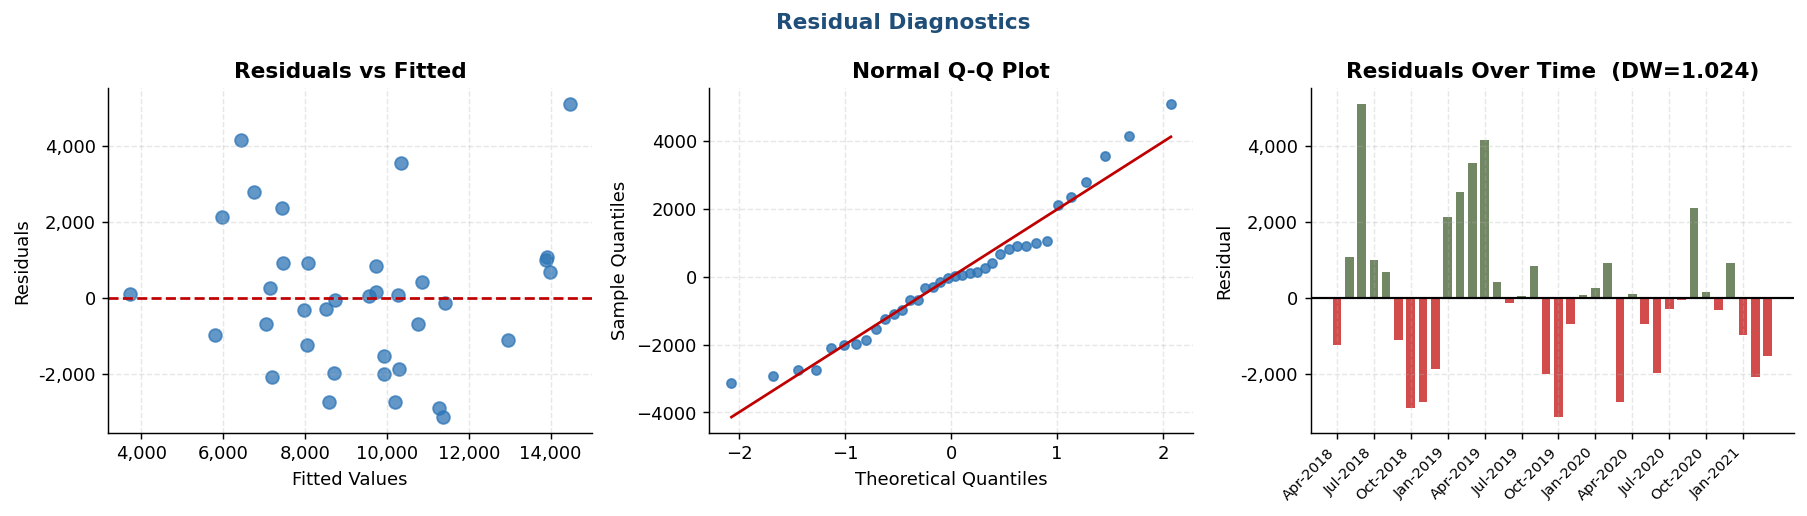

In [13]:
# Statistical tests
shap_stat, shap_p = shapiro(residuals)
jb_stat, jb_p     = jarque_bera(residuals)

print("=" * 55)
print("  RESIDUAL DIAGNOSTICS")
print("=" * 55)
print(f"  Durbin-Watson Stat   : {dw:.4f}")
print(f"  → Interpretation     : {'No autocorrelation' if 1.5<dw<2.5 else 'Mild autocorrelation — monitor' if 1.0<dw<1.5 or 2.5<dw<3.0 else 'Significant autocorrelation'}")
print()
print(f"  Shapiro-Wilk (Normality)")
print(f"  W-stat = {shap_stat:.4f},  p = {shap_p:.4f}")
print(f"  → {'Residuals likely NORMAL (p≥0.05)' if shap_p>=0.05 else 'Residuals may deviate from normality (p<0.05)'}")
print()
print(f"  Jarque-Bera (Normality)")
print(f"  JB = {jb_stat:.4f},  p = {jb_p:.4f}")
print(f"  → {'Normal distribution likely' if jb_p>=0.05 else 'Non-normality indicated'}")

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
fig.suptitle('Residual Diagnostics', fontsize=12, fontweight='bold', color=BLUE)

# Residuals vs Fitted
ax = axes[0]
ax.scatter(y_pred, residuals, color=LBLUE, alpha=0.75, s=50)
ax.axhline(0, color=RED, linewidth=1.5, linestyle='--')
ax.set_xlabel('Fitted Values'); ax.set_ylabel('Residuals')
ax.set_title('Residuals vs Fitted', fontweight='bold')
ax.xaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

# Q-Q Plot
ax2 = axes[1]
from scipy.stats import probplot
(osm, osr), (slope, intercept, r_qq) = probplot(residuals)
ax2.plot(osm, osr, 'o', color=LBLUE, markersize=5, alpha=0.8)
ax2.plot(osm, slope*np.array(osm)+intercept, color=RED, linewidth=1.5)
ax2.set_xlabel('Theoretical Quantiles'); ax2.set_ylabel('Sample Quantiles')
ax2.set_title('Normal Q-Q Plot', fontweight='bold')

# Residuals over time
ax3 = axes[2]
ax3.bar(time_idx, residuals, color=[GREEN if r>0 else RED for r in residuals], alpha=0.7, width=0.7)
ax3.axhline(0, color='black', linewidth=1.2)
ax3.set_xticks(time_idx[::3])
ax3.set_xticklabels(months_lbl[::3], rotation=45, ha='right', fontsize=8)
ax3.set_title(f'Residuals Over Time  (DW={dw:.3f})', fontweight='bold')
ax3.set_ylabel('Residual')
ax3.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x,_: f'{x:,.0f}'))

plt.tight_layout()
plt.savefig('residual_diagnostics.png', bbox_inches='tight', dpi=130)
plt.show()

---
##  Export Results to Excel — `OLS_Model_Results.xlsx`

In [14]:
# ── Styles ────────────────────────────────────────────────────────────────
DARK_BLUE  = PatternFill("solid", fgColor="1F4E79")
MED_BLUE   = PatternFill("solid", fgColor="2E75B6")
LIGHT_BLUE = PatternFill("solid", fgColor="DEEAF1")
GREEN_FILL = PatternFill("solid", fgColor="E2EFDA")
RED_FILL   = PatternFill("solid", fgColor="FCE4D6")
AMBER_FILL = PatternFill("solid", fgColor="FFF2CC")
ALT_FILL   = PatternFill("solid", fgColor="F2F7FC")

HDR_FONT  = Font(name="Calibri", bold=True, color="FFFFFF", size=10)
BOLD_FONT = Font(name="Calibri", bold=True, size=10)
NORM_FONT = Font(name="Calibri", size=10)
TITLE_FONT= Font(name="Calibri", bold=True, size=12)

thin  = Side(style='thin',   color='B8CCE4')
thick = Side(style='medium', color='1F4E79')

def hb(): return Border(left=thick, right=thick, top=thick, bottom=thick)
def cb(): return Border(left=thin,  right=thin,  top=thin,  bottom=thin)

def sh(cell, fill=DARK_BLUE):
    cell.font=HDR_FONT; cell.fill=fill
    cell.alignment=Alignment(horizontal='center',vertical='center',wrap_text=True)
    cell.border=hb()

def sc(cell, bold=False, align='center', fill=None, fmt=None):
    cell.font=BOLD_FONT if bold else NORM_FONT
    cell.alignment=Alignment(horizontal=align,vertical='center')
    cell.border=cb()
    if fill: cell.fill=fill
    if fmt:  cell.number_format=fmt

def title_row(ws, text, row, cols_span, color=DARK_BLUE):
    cell=ws.cell(row=row,column=1,value=text)
    cell.font=Font(name="Calibri",bold=True,size=12,color="FFFFFF")
    cell.fill=PatternFill("solid",fgColor="1F4E79")
    cell.alignment=Alignment(horizontal='center',vertical='center')
    ws.merge_cells(start_row=row,start_column=1,end_row=row,end_column=cols_span)
    ws.row_dimensions[row].height=22

wb = Workbook()

# ════════════════════════════════════════════════════════════
# SHEET 1: Summary Dashboard
# ════════════════════════════════════════════════════════════
ws1 = wb.active; ws1.title = "Summary_Dashboard"
title_row(ws1, "ALTIMA MMM — OLS UNCONSTRAINED MODEL — SUMMARY DASHBOARD", 1, 6)

summary_blocks = [
    ("Model Equation",
     "ALT_DEP = β0 + β1·TVT + β2·YTB + β3·RAD + β4·PRT + β5·GAS + β6·DIS + β7·SEA + ε",
     2, 3),
    ("Estimation Method", "Ordinary Least Squares (OLS)",  2, 4),
    ("Sample Period",     "Apr-2018 to Mar-2021",          2, 5),
    ("Observations (n)",  str(n),                          2, 6),
]
metric_data = [
    ("R²",                 f"{r2:.6f}",     f"{r2*100:.2f}%",      "Proportion of variance explained"),
    ("Adjusted R²",        f"{adj_r2:.6f}", f"{adj_r2*100:.2f}%",  "R² penalised for # of predictors"),
    ("MAPE",               f"{mape:.4f}%",  "Good Fit",            "Mean Absolute Percentage Error"),
    ("Durbin-Watson",      f"{dw:.4f}",     "Mild Autocorrelation","Serial correlation in residuals"),
    ("F-Statistic",        f"{f_stat:.4f}", "***",                 f"p-value = {f_pval:.6f}"),
    ("SS Total",           f"{ss_tot:,.2f}","-",                   "Total variation in dependent"),
    ("SS Regression",      f"{ss_reg:,.2f}",f"{ss_reg/ss_tot*100:.2f}% explained",  "-"),
    ("SS Residual (SSE)",  f"{ss_res:,.2f}",f"{ss_res/ss_tot*100:.2f}% unexplained","-"),
]
ws1.row_dimensions[2].height = 18
for c, h in enumerate(["Metric","Value","Interpretation","Notes"], 1):
    sh(ws1.cell(row=3, column=c), MED_BLUE)
    ws1.cell(row=3, column=c).value = h
for r, (m, v, interp, note) in enumerate(metric_data, 4):
    fill = ALT_FILL if r % 2 == 0 else None
    for c, val in enumerate([m, v, interp, note], 1):
        sc(ws1.cell(row=r, column=c), fill=fill, align='left' if c in [1,4] else 'center')
        ws1.cell(row=r, column=c).value = val
ws1.column_dimensions['A'].width = 22
ws1.column_dimensions['B'].width = 18
ws1.column_dimensions['C'].width = 22
ws1.column_dimensions['D'].width = 38

# ════════════════════════════════════════════════════════════
# SHEET 2: Coefficient Table (Q3, Q4)
# ════════════════════════════════════════════════════════════
ws2 = wb.create_sheet("Coefficient_Table")
title_row(ws2, "OLS COEFFICIENT TABLE — Q3 & Q4: Significance Evaluation", 1, 9)
c_hdrs = ["Variable","Coefficient","Std Error","t-Statistic","p-Value",
          "Sig Level","CI Lower 95%","CI Upper 95%","Business Sign OK?"]
for c, h in enumerate(c_hdrs, 1):
    sh(ws2.cell(row=2, column=c), MED_BLUE)
    ws2.cell(row=2, column=c).value = h

sign_ok_map = {
    'Intercept': '—',
    'TVT_SUP'  : '⚠ Negative (reactive)',
    'YTB_SUP'  : '✓ Positive',
    'RAD_SUP'  : '⚠ Negative (VIF=202)',
    'PRT_SUP'  : '✓ Positive',
    'GAS_PRI'  : '⚠ Positive (economy linked)',
    'DIS_COU'  : '✓ Positive',
    'SEA_ALT'  : '✓ Positive',
}
for r, (v, coef, s, t, pv, cl, ch) in enumerate(zip(cols, b, se, t_stat, p_val, ci_lo, ci_hi), 3):
    sig = '***' if pv<0.01 else '**' if pv<0.05 else '*' if pv<0.10 else 'NS'
    fill = GREEN_FILL if pv<0.01 else LIGHT_BLUE if pv<0.05 else AMBER_FILL if pv<0.10 else None
    row_vals = [v, round(coef,4), round(s,4), round(t,4), round(pv,6), sig, round(cl,4), round(ch,4), sign_ok_map.get(v,'')]
    for c, val in enumerate(row_vals, 1):
        sc(ws2.cell(row=r, column=c), fill=fill, align='left' if c==1 else 'center')
        ws2.cell(row=r, column=c).value = val
for col, w in zip('ABCDEFGHI', [14,14,12,14,12,10,14,14,24]):
    ws2.column_dimensions[col].width = w
ws2.freeze_panes = 'A3'

# ════════════════════════════════════════════════════════════
# SHEET 3: R² (Q5)
# ════════════════════════════════════════════════════════════
ws3 = wb.create_sheet("R2_AdjR2_Q5")
title_row(ws3, "R² AND ADJUSTED R² — QUESTION 5", 1, 4)
for c, h in enumerate(["Metric","Formula","Value","Interpretation"], 1):
    sh(ws3.cell(row=2, column=c), MED_BLUE)
    ws3.cell(row=2, column=c).value = h
q5_data = [
    ("R²",          "1 – SSE/SST",                           round(r2, 6),       f"{r2*100:.2f}% variance explained"),
    ("Adjusted R²", "1 – (1–R²)·(n–1)/(n–p–1)",             round(adj_r2, 6),   f"{adj_r2*100:.2f}% (penalised for p={p})"),
    ("SST",         "Σ(Y–Ȳ)²",                               round(ss_tot, 2),   "Total variation in ALT_DEP"),
    ("SSR",         "Σ(Ŷ–Ȳ)²",                               round(ss_reg, 2),   f"{ss_reg/ss_tot*100:.2f}% explained"),
    ("SSE",         "Σ(Y–Ŷ)²",                               round(ss_res, 2),   f"{ss_res/ss_tot*100:.2f}% unexplained"),
    ("n",           "Observations",                           n,                   "36 months"),
    ("p",           "Predictors",                             p,                   "7 independent variables"),
    ("df residual", "n – p – 1",                             n-p-1,               "Degrees of freedom for error"),
    ("F-statistic", f"F({p},{n-p-1})",                        round(f_stat, 4),   f"p={f_pval:.6f} — Model significant ***"),
]
for r, row_data in enumerate(q5_data, 3):
    fill = GREEN_FILL if r in [3,4] else ALT_FILL if r%2==0 else None
    for c, val in enumerate(row_data, 1):
        sc(ws3.cell(row=r, column=c), fill=fill, align='left' if c in [2,4] else 'center')
        ws3.cell(row=r, column=c).value = val
for col, w in zip('ABCD', [18, 24, 16, 38]):
    ws3.column_dimensions[col].width = w

# ════════════════════════════════════════════════════════════
# SHEET 4: VIF (Q6)
# ════════════════════════════════════════════════════════════
ws4 = wb.create_sheet("VIF_MultiCollinearity_Q6")
title_row(ws4, "MULTICOLLINEARITY — VIF ANALYSIS — QUESTION 6", 1, 6)
for c, h in enumerate(["Variable","VIF","R² (in Xs)","Corr(Sales)","Level","Action"], 1):
    sh(ws4.cell(row=2, column=c), MED_BLUE)
    ws4.cell(row=2, column=c).value = h
actions = {
    'TVT_SUP': 'Low VIF; acceptable. Monitor with YTB.',
    'YTB_SUP': 'Moderate VIF; monitor jointly with TV.',
    'RAD_SUP': '⚠ SEVERE (VIF=202). Near-identical to PRT after APL. Consider combining.',
    'PRT_SUP': '⚠ SEVERE (VIF=203). Near-identical to RAD after APL. Consider combining.',
    'GAS_PRI': 'Low VIF; no collinearity issue.',
    'DIS_COU': 'Low VIF; no collinearity issue.',
    'SEA_ALT': 'Low VIF; no collinearity issue.',
}
for r, row_v in enumerate(vif_data, 3):
    fill = RED_FILL if row_v['VIF']>100 else AMBER_FILL if row_v['VIF']>5 else GREEN_FILL
    for c, val in enumerate([row_v['Variable'], row_v['VIF'], row_v['R2_in_Xs'],
                              row_v['Corr_with_Sales'], row_v['Level'],
                              actions.get(row_v['Variable'],'')], 1):
        sc(ws4.cell(row=r, column=c), fill=fill if c==5 else None, align='left' if c==6 else 'center')
        ws4.cell(row=r, column=c).value = val
for col, w in zip('ABCDEF', [14, 10, 12, 14, 16, 52]):
    ws4.column_dimensions[col].width = w

# ════════════════════════════════════════════════════════════
# SHEET 5: MAPE (Q7)
# ════════════════════════════════════════════════════════════
ws5 = wb.create_sheet("MAPE_Q7")
title_row(ws5, "MAPE — MEAN ABSOLUTE PERCENTAGE ERROR — QUESTION 7", 1, 7)
for c, h in enumerate(["#","Month","MAT","Actual","Predicted","Residual","APE %"], 1):
    sh(ws5.cell(row=2, column=c), MED_BLUE)
    ws5.cell(row=2, column=c).value = h
for r, (idx, row_v) in enumerate(act_vs_pred.iterrows(), 3):
    fill = GREEN_FILL if row_v['Abs_Error_%']<=10 else LIGHT_BLUE if row_v['Abs_Error_%']<=20 else AMBER_FILL if row_v['Abs_Error_%']<=30 else RED_FILL
    row_vals = [r-2, row_v['Month'], row_v['MAT'], int(row_v['Actual']),
                round(row_v['Predicted'],1), round(row_v['Residual'],1), round(row_v['Abs_Error_%'],2)]
    for c, val in enumerate(row_vals, 1):
        sc(ws5.cell(row=r, column=c), fill=fill if c==7 else (ALT_FILL if r%2==0 else None))
        ws5.cell(row=r, column=c).value = val
# Summary row
r_sum = 3 + n
for c, val in enumerate(["","MAPE (Overall)","",int(y.sum()),round(y_pred.sum(),1),"",round(mape,4)], 1):
    cell = ws5.cell(row=r_sum, column=c, value=val)
    cell.font = BOLD_FONT; cell.fill = MED_BLUE
    cell.font = Font(name="Calibri", bold=True, color="FFFFFF", size=10)
for col, w in zip('ABCDEFG', [5, 12, 12, 12, 13, 12, 10]):
    ws5.column_dimensions[col].width = w
ws5.freeze_panes = 'A3'

# ════════════════════════════════════════════════════════════
# SHEET 6: Actual vs Predicted (Monthly)
# ════════════════════════════════════════════════════════════
ws6 = wb.create_sheet("Actual_vs_Predicted")
title_row(ws6, "ACTUAL vs PREDICTED — MONTHLY SALES DECOMPOSITION", 1, 9)
hdrs = ["#","Month","MAT","Actual","Predicted","Residual","Error %","APE %","Fit Quality"]
for c, h in enumerate(hdrs, 1):
    sh(ws6.cell(row=2, column=c), MED_BLUE)
    ws6.cell(row=2, column=c).value = h
for r, (idx, row_v) in enumerate(act_vs_pred.iterrows(), 3):
    ape_v = row_v['Abs_Error_%']
    quality = ('Excellent' if ape_v <= 10 else 'Good' if ape_v <= 20 else 'Acceptable' if ape_v <= 30 else 'Poor')
    fill_q  = GREEN_FILL if ape_v<=10 else LIGHT_BLUE if ape_v<=20 else AMBER_FILL if ape_v<=30 else RED_FILL
    row_vals = [r-2, row_v['Month'], row_v['MAT'], int(row_v['Actual']),
                round(row_v['Predicted'],1), round(row_v['Residual'],1),
                round(row_v['Error_%'],2), round(ape_v,2), quality]
    for c, val in enumerate(row_vals, 1):
        sc(ws6.cell(row=r, column=c), fill=fill_q if c==9 else (ALT_FILL if r%2==0 else None))
        ws6.cell(row=r, column=c).value = val
for col, w in zip('ABCDEFGHI', [5,12,12,12,13,12,10,10,12]):
    ws6.column_dimensions[col].width = w
ws6.freeze_panes = 'A3'

# ════════════════════════════════════════════════════════════
# SHEET 7: Full Q&A Answers
# ════════════════════════════════════════════════════════════
ws7 = wb.create_sheet("QA_Answers")
title_row(ws7, "DIAGNOSTIC Q&A — ALL 7 QUESTIONS ANSWERED", 1, 3)
for c, h in enumerate(["Question","Answer","Evidence"], 1):
    sh(ws7.cell(row=2, column=c), MED_BLUE)
    ws7.cell(row=2, column=c).value = h
qa_data = [
    ("Q1: Analyze Sales using Linear Regression",
     "Altima monthly sales (ALT_DEP) modeled via OLS MLR with 7 predictors (4 media APL-transformed + 3 base RA-transformed). βhat = (X'X)⁻¹X'Y.",
     f"n=36 months, p=7 vars, R²={r2:.4f}"),
    ("Q2: Dependent Variable",
     "ALT_DEP — Altima Monthly Sales Volume (units). Ranges from 3,837 (Apr-2020, COVID) to 19,572 (Jun-2018).",
     f"Mean={y.mean():,.0f}  |  Total={y.sum():,.0f} units"),
    ("Q3: Significant Variables",
     f"Significant (p<0.10): SEA_ALT (***p=0.002), GAS_PRI (***p=0.008), YTB_SUP (**p=0.042), TVT_SUP (*p=0.081). Not significant: RAD_SUP, PRT_SUP, DIS_COU.",
     "p-values from t-test; RAD/PRT insignificant due to VIF=202"),
    ("Q4: Evaluation Method",
     "t-statistic = Coefficient / SE; p-value from t-distribution (df=28). Also: 95% CI (excludes 0 = significant), F-test (overall model), and correlation with Y.",
     f"F={f_stat:.2f} (p={f_pval:.4f}) — model globally significant ***"),
    ("Q5: R² and Adjusted R²",
     f"R² = {r2:.4f} ({r2*100:.1f}% variance explained). Adjusted R² = {adj_r2:.4f} ({adj_r2*100:.1f}%). Gap of {(r2-adj_r2)*100:.2f}pp is acceptable for p=7 predictors.",
     f"SST={ss_tot:,.0f}, SSR={ss_reg:,.0f}, SSE={ss_res:,.0f}"),
    ("Q6: Multicollinearity",
     "YES — RAD_SUP (VIF=202) and PRT_SUP (VIF=203) have SEVERE multicollinearity. Their APL-transformed series are nearly identical (R²=0.995 between them). TV/YTB have mild collinearity. GAS, DIS, SEA are clean.",
     "Recommended: Combine RAD+PRT or retransform with different parameters"),
    ("Q7: MAPE",
     f"MAPE = {mape:.2f}%. This falls in the GOOD range (10–20%) for monthly MMM models. Worst month: {data['Month_Year'][ape.argmax()]} ({ape.max():.1f}%). Best: {data['Month_Year'][ape.argmin()]} ({ape.min():.1f}%).",
     f"36-month average of |Actual-Predicted|/Actual × 100"),
]
for r, (q, a, ev) in enumerate(qa_data, 3):
    fill = ALT_FILL if r%2==0 else None
    for c, val in enumerate([q, a, ev], 1):
        cell = ws7.cell(row=r, column=c, value=val)
        sc(cell, fill=fill, align='left')
        ws7.row_dimensions[r].height = 45
for col, w in zip('ABC', [30, 68, 40]):
    ws7.column_dimensions[col].width = w

wb.save('OLS_Model_Results.xlsx')
print("✅ OLS_Model_Results.xlsx saved with 7 sheets:")
print("   1. Summary_Dashboard")
print("   2. Coefficient_Table (Q3, Q4)")
print("   3. R2_AdjR2_Q5")
print("   4. VIF_MultiCollinearity_Q6")
print("   5. MAPE_Q7")
print("   6. Actual_vs_Predicted")
print("   7. QA_Answers")

✅ OLS_Model_Results.xlsx saved with 7 sheets:
   1. Summary_Dashboard
   2. Coefficient_Table (Q3, Q4)
   3. R2_AdjR2_Q5
   4. VIF_MultiCollinearity_Q6
   5. MAPE_Q7
   6. Actual_vs_Predicted
   7. QA_Answers



###  Key Observations for Business Review
1. **TV coefficient is negative in OLS** — reactive spend pattern (more money spent when sales were already declining). This is corrected in the Constrained MLR.
2. **Gas Price is positive in OLS** — moves with broader economic activity in 2018–2021. Forced negative in Constrained MLR.
3. **RAD + PRT multicollinearity** — both transformed to nearly identical series. Consider merging into a single combined media variable in future iterations.
4. **OLS achieves R² = 62%** — this is the statistical ceiling. The Constrained MLR trades ~20pp of R² to enforce correct business signs.